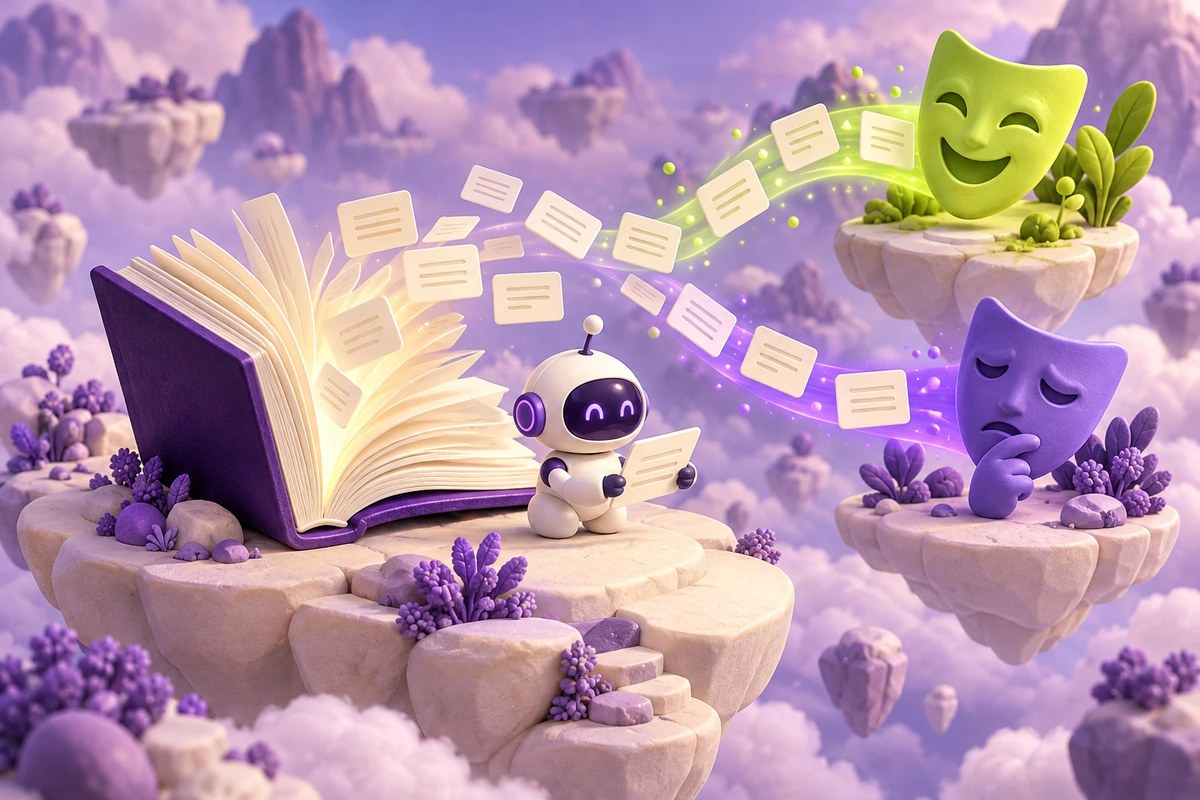

AI PATH · Нейросети для текста · Урок 034

# Yelp: выбор лучшей эпохи LSTM

Контрольная точка, независимый тест и предсказание для собственного отзыва.

**Архивный учебный материал.** Код и сохранённые результаты относятся к исходному ноутбуку. Оформление не означает новый запуск или подтверждение старых метрик. Перед выполнением проверьте зависимости и ограничения.

<a id="ai-034-goal"></a>
## Что вы разберёте

Проверять, какая именно версия модели оценивается после обучения.

### Перед началом

- Последовательности и LSTM
- Обучающая, проверочная и тестовая части

### Что понадобится

- TensorFlow/Keras, Pandas, NumPy и Matplotlib
- Архив Yelp polarity с train.csv и test.csv
- Colab/Linux shell и возможность записать best_model.h5

## Навигация по уроку

- [Цель и подготовка](#ai-034-goal)
- [Карта урока](#ai-034-map)
- [Корпус и файлы](#ai-034-section-01)
- [Подготовка цели](#ai-034-section-02)
- [Единые преобразования](#ai-034-section-03)
- [Архитектура LSTM](#ai-034-section-04)
- [Контрольная точка](#ai-034-section-05)
- [Оценка выбранных весов](#ai-034-section-06)
- [Разбор своего отзыва](#ai-034-section-07)
- [Проверьте понимание](#ai-034-practice)
- [Источники и ограничения](#ai-034-provenance)

<a id="ai-034-map"></a>
## Карта урока

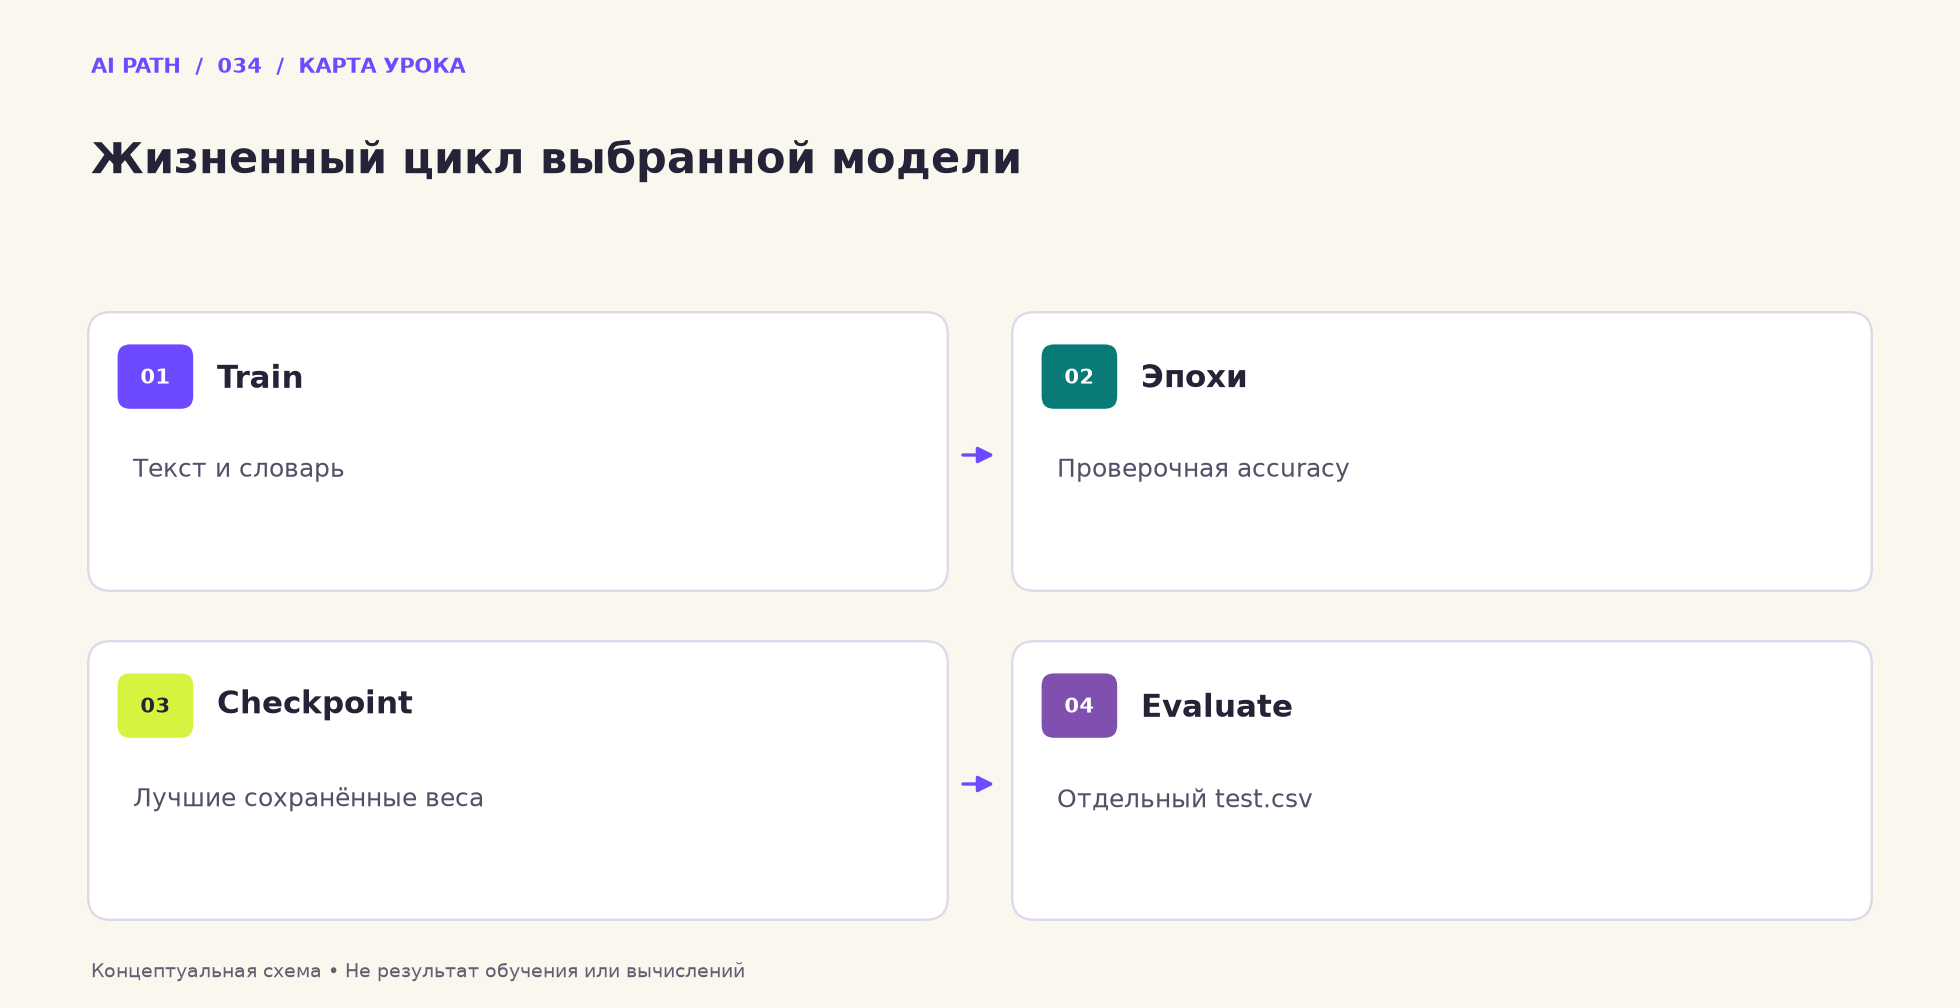

Схема показывает последовательность идей. Она не содержит результатов нового обучения или вычислений.

1. **Train** — Текст и словарь
2. **Эпохи** — Проверочная accuracy
3. **Checkpoint** — Лучшие сохранённые веса
4. **Evaluate** — Отдельный test.csv

<a href="https://colab.research.google.com/github/safal207/hello-world/blob/master/%D0%9E%D0%BF%D1%80%D0%B5%D0%B4%D0%B5%D0%BB%D0%B5%D0%BD%D0%B8%D0%B5_%D1%82%D0%BE%D0%BD%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D1%81%D1%82%D0%B8_%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2_YELP_%D1%87%D0%B5%D1%80%D0%B5%D0%B7_LSTM_%D1%81%D0%B5%D1%82%D1%8C_%D1%82%D0%BE%D1%87%D0%BD%D0%BE%D1%81%D1%82%D1%8C_95_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Определение тональности текстов отзывов на сайте [YELP](https://www.yelp.com/dataset/challenge) сетью LSTM

Учебный курс "[Нейросети для анализа текстов](https://www.asozykin.ru/courses/nnpython)".

Чтобы запускать и редактировать код, сохраните копию этого ноутбука себе (File->Save a copy in Drive...). Свою копию вы сможете изменять и запускать.

Не забудьте подключить GPU, чтобы сеть обучалась быстрее (Runtime -> Change Runtime Type -> Hardware Accelerator -> GPU).

In [1]:
%tensorflow_version 2.x
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Embedding, GRU, LSTM
from tensorflow.keras import utils
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.callbacks import ModelCheckpoint
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline 

In [2]:
num_words = 10000
max_review_len = 100

<a id="ai-034-section-01"></a>
## 01 · Корпус и файлы

Убедитесь, что обучающие и тестовые отзывы загружаются из разных файлов.

_Далее — исходные ячейки учебного материала._

## Загрузка набора данных

In [3]:
!wget https://www.dropbox.com/s/ufbhk3kadtnn6h0/yelp_review_polarity_csv.tgz?dl=1 -O yelp_review_polarity_csv.tgz

--2020-11-12 11:09:22--  https://www.dropbox.com/s/ufbhk3kadtnn6h0/yelp_review_polarity_csv.tgz?dl=1
Resolving www.dropbox.com (www.dropbox.com)... 162.125.82.1, 2620:100:6032:1::a27d:5201
Connecting to www.dropbox.com (www.dropbox.com)|162.125.82.1|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: /s/dl/ufbhk3kadtnn6h0/yelp_review_polarity_csv.tgz [following]
--2020-11-12 11:09:22--  https://www.dropbox.com/s/dl/ufbhk3kadtnn6h0/yelp_review_polarity_csv.tgz
Reusing existing connection to www.dropbox.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://uc291e56a053de355189ddf0dd94.dl.dropboxusercontent.com/cd/0/get/BDCFlIM82Yh1KEPB6VUma_4E_Wmf92eBuJ-zoneZVHuP1NTAS9llOl8WnC65XiAqcR2lx58AOUHikdEsRlr7ZFLWvlGEK8IxvTOSciH1RrKDXEcXpTlUqeKbUc2hsOzUsfI/file?dl=1# [following]
--2020-11-12 11:09:22--  https://uc291e56a053de355189ddf0dd94.dl.dropboxusercontent.com/cd/0/get/BDCFlIM82Yh1KEPB6VUma_4E_Wmf92eBuJ-zoneZVHuP1NTAS9llOl8WnC65X

In [4]:
!tar -xvf yelp_review_polarity_csv.tgz

yelp_review_polarity_csv/
yelp_review_polarity_csv/train.csv
yelp_review_polarity_csv/readme.txt
yelp_review_polarity_csv/test.csv


## Просматриваем данные

In [5]:
!cat yelp_review_polarity_csv/readme.txt

Yelp Review Polarity Dataset

Version 1, Updated 09/09/2015

ORIGIN

The Yelp reviews dataset consists of reviews from Yelp. It is extracted from the Yelp Dataset Challenge 2015 data. For more information, please refer to http://www.yelp.com/dataset_challenge

The Yelp reviews polarity dataset is constructed by Xiang Zhang (xiang.zhang@nyu.edu) from the above dataset. It is first used as a text classification benchmark in the following paper: Xiang Zhang, Junbo Zhao, Yann LeCun. Character-level Convolutional Networks for Text Classification. Advances in Neural Information Processing Systems 28 (NIPS 2015).


DESCRIPTION

The Yelp reviews polarity dataset is constructed by considering stars 1 and 2 negative, and 3 and 4 positive. For each polarity 280,000 training samples and 19,000 testing samples are take randomly. In total there are 560,000 trainig samples and 38,000 testing samples. Negative polarity is class 1, and positive class 2.

The files train.csv and test.csv contain all the

In [6]:
!head yelp_review_polarity_csv/train.csv

"1","Unfortunately, the frustration of being Dr. Goldberg's patient is a repeat of the experience I've had with so many other doctors in NYC -- good doctor, terrible staff.  It seems that his staff simply never answers the phone.  It usually takes 2 hours of repeated calling to get an answer.  Who has time for that or wants to deal with it?  I have run into this problem with many other doctors and I just don't get it.  You have office workers, you have patients with medical needs, why isn't anyone answering the phone?  It's incomprehensible and not work the aggravation.  It's with regret that I feel that I have to give Dr. Goldberg 2 stars."
"2","Been going to Dr. Goldberg for over 10 years. I think I was one of his 1st patients when he started at MHMG. He's been great over the years and is really all about the big picture. It is because of him, not my now former gyn Dr. Markoff, that I found out I have fibroids. He explores all options with you and is very patient and understanding. H

In [7]:
!head yelp_review_polarity_csv/test.csv

"2","Contrary to other reviews, I have zero complaints about the service or the prices. I have been getting tire service here for the past 5 years now, and compared to my experience with places like Pep Boys, these guys are experienced and know what they're doing. \nAlso, this is one place that I do not feel like I am being taken advantage of, just because of my gender. Other auto mechanics have been notorious for capitalizing on my ignorance of cars, and have sucked my bank account dry. But here, my service and road coverage has all been well explained - and let up to me to decide. \nAnd they just renovated the waiting room. It looks a lot better than it did in previous years."
"1","Last summer I had an appointment to get new tires and had to wait a super long time. I also went in this week for them to fix a minor problem with a tire they put on. They \""fixed\"" it for free, and the very next morning I had the same issue. I called to complain, and the \""manager\"" didn't even apolog

In [8]:
!wc -l yelp_review_polarity_csv/train.csv
!wc -l yelp_review_polarity_csv/test.csv

560000 yelp_review_polarity_csv/train.csv
38000 yelp_review_polarity_csv/test.csv


<a id="ai-034-section-02"></a>
## 02 · Подготовка цели

Метки Class-1 должны соответствовать бинарному sigmoid-выходу.

_Далее — исходные ячейки учебного материала._

## Загружаем данные в память

Читаем данные из файла

In [9]:
train = pd.read_csv('yelp_review_polarity_csv/train.csv', 
                    header=None, 
                    names=['Class', 'Review'])

In [10]:
train

,Class,Review
0,1,"Unfortunately, the frustration of being Dr. Go..."
1,2,Been going to Dr. Goldberg for over 10 years. ...
2,1,I don't know what Dr. Goldberg was like before...
3,1,I'm writing this review to give you a heads up...
4,2,All the food is great here. But the best thing...
...,...,...
559995,2,Ryan was as good as everyone on yelp has claim...
559996,2,Professional \nFriendly\nOn time AND affordabl...
559997,1,Phone calls always go to voicemail and message...
559998,1,Looks like all of the good reviews have gone t...


Выделяем данные для обучения

In [11]:
reviews = train['Review']

In [12]:
reviews[:5]

0    Unfortunately, the frustration of being Dr. Go...
1    Been going to Dr. Goldberg for over 10 years. ...
2    I don't know what Dr. Goldberg was like before...
3    I'm writing this review to give you a heads up...
4    All the food is great here. But the best thing...
Name: Review, dtype: object

Выделяем правильные ответы

In [13]:
y_train = train['Class'] - 1

In [14]:
y_train

0         0
1         1
2         0
3         0
4         1
         ..
559995    1
559996    1
559997    0
559998    0
559999    1
Name: Class, Length: 560000, dtype: int64

<a id="ai-034-section-03"></a>
## 03 · Единые преобразования

Словарь 10 000 и длина 100 фиксируются по обучению и применяются к тесту.

_Далее — исходные ячейки учебного материала._

## Токенизация текста

In [15]:
reviews[:5]

0    Unfortunately, the frustration of being Dr. Go...
1    Been going to Dr. Goldberg for over 10 years. ...
2    I don't know what Dr. Goldberg was like before...
3    I'm writing this review to give you a heads up...
4    All the food is great here. But the best thing...
Name: Review, dtype: object

Создаем токенизатор Keras

In [16]:
tokenizer = Tokenizer(num_words=num_words)

Обучаем токенизатор на отзывах Yelp

In [17]:
tokenizer.fit_on_texts(reviews)

Просматриваем словарь токенизатора

In [18]:
tokenizer.word_index

{'the': 1,
 'and': 2,
 'i': 3,
 'to': 4,
 'a': 5,
 'was': 6,
 'of': 7,
 'it': 8,
 'for': 9,
 'in': 10,
 'is': 11,
 'n': 12,
 'that': 13,
 'my': 14,
 'we': 15,
 'this': 16,
 'but': 17,
 'with': 18,
 'they': 19,
 'you': 20,
 'on': 21,
 'not': 22,
 'have': 23,
 'had': 24,
 'at': 25,
 'were': 26,
 'so': 27,
 'are': 28,
 'food': 29,
 'be': 30,
 'place': 31,
 'me': 32,
 'there': 33,
 'good': 34,
 'as': 35,
 'out': 36,
 'all': 37,
 'like': 38,
 'if': 39,
 'just': 40,
 'our': 41,
 'very': 42,
 'get': 43,
 'one': 44,
 'here': 45,
 'time': 46,
 'when': 47,
 'up': 48,
 'or': 49,
 'from': 50,
 'great': 51,
 'service': 52,
 'would': 53,
 'back': 54,
 'their': 55,
 'about': 56,
 'no': 57,
 'go': 58,
 'an': 59,
 'what': 60,
 'really': 61,
 'he': 62,
 "it's": 63,
 'she': 64,
 'which': 65,
 'will': 66,
 'some': 67,
 'only': 68,
 'been': 69,
 'us': 70,
 'your': 71,
 'because': 72,
 'more': 73,
 'even': 74,
 'can': 75,
 'them': 76,
 'by': 77,
 "don't": 78,
 'got': 79,
 'other': 80,
 'after': 81,
 'do': 8

Преобразуем отзывы Yelp в числовое представление

In [19]:
sequences = tokenizer.texts_to_sequences(reviews)

Просматриваем отзывы в числовом представлении

In [20]:
index = 0
print(reviews[index])
print(sequences[index])

Unfortunately, the frustration of being Dr. Goldberg's patient is a repeat of the experience I've had with so many other doctors in NYC -- good doctor, terrible staff.  It seems that his staff simply never answers the phone.  It usually takes 2 hours of repeated calling to get an answer.  Who has time for that or wants to deal with it?  I have run into this problem with many other doctors and I just don't get it.  You have office workers, you have patients with medical needs, why isn't anyone answering the phone?  It's incomprehensible and not work the aggravation.  It's with regret that I feel that I have to give Dr. Goldberg 2 stars.
[707, 1, 4339, 7, 173, 939, 1665, 11, 5, 2161, 7, 1, 137, 112, 24, 18, 27, 189, 80, 3128, 10, 2636, 34, 1416, 462, 129, 8, 519, 13, 177, 129, 803, 88, 3812, 1, 446, 8, 392, 841, 115, 360, 7, 4136, 1438, 4, 43, 59, 1266, 118, 95, 46, 9, 13, 49, 1687, 4, 418, 18, 8, 3, 23, 563, 178, 16, 460, 18, 189, 80, 3128, 2, 3, 40, 78, 43, 8, 20, 23, 644, 1343, 20, 23

In [21]:
tokenizer.word_index['frustration']

4339

Ограничиваем длину отзывов

In [22]:
x_train = pad_sequences(sequences, maxlen=max_review_len)

In [23]:
x_train[:5]

array([[   7,    1,  137,  112,   24,   18,   27,  189,   80, 3128,   10,
        2636,   34, 1416,  462,  129,    8,  519,   13,  177,  129,  803,
          88, 3812,    1,  446,    8,  392,  841,  115,  360,    7, 4136,
        1438,    4,   43,   59, 1266,  118,   95,   46,    9,   13,   49,
        1687,    4,  418,   18,    8,    3,   23,  563,  178,   16,  460,
          18,  189,   80, 3128,    2,    3,   40,   78,   43,    8,   20,
          23,  644, 1343,   20,   23, 3252,   18, 2921,  637,  227,  430,
         476, 4312,    1,  446,   63,    2,   22,  215,    1,   63,   18,
        2269,   13,    3,  249,   13,    3,   23,    4,  163,  939,  115,
         237],
       [   0,    0,    0,    0,    0,    0,    0,    0,    0,   69,  116,
           4,  939,    9,   94,  201,  274,    3,  142,    3,    6,   44,
           7,  177, 2084, 3252,   47,   62,  422,   25, 1334,   69,   51,
          94,    1,  274,    2,   11,   61,   37,   56,    1,  219, 1403,
           8,   11,   7

<a id="ai-034-section-04"></a>
## 04 · Архитектура LSTM

Embedding(64) и LSTM(128) задают проверяемую базовую модель.

_Далее — исходные ячейки учебного материала._

## Создаем нейронную сеть

In [24]:
model = Sequential()
model.add(Embedding(num_words, 64, input_length=max_review_len))
model.add(LSTM(128))
model.add(Dense(1, activation='sigmoid'))

In [25]:
model.compile(optimizer='adam', 
              loss='binary_crossentropy', 
              metrics=['accuracy'])

<a id="ai-034-section-05"></a>
## 05 · Контрольная точка

Разделите состояние последней эпохи и веса, сохранённые по лучшей val_accuracy.

_Далее — исходные ячейки учебного материала._

## Обучаем нейронную сеть

Создаем callback для сохранения нейронной сети на каждой эпохе, если качество работы на проверочном наборе данных улучшилось. Сеть сохраняется в файл `best_model.h5`

In [26]:
model_save_path = 'best_model.h5'
checkpoint_callback = ModelCheckpoint(model_save_path, 
                                      monitor='val_accuracy',
                                      save_best_only=True,
                                      verbose=1)

In [27]:
history = model.fit(x_train, 
                    y_train, 
                    epochs=5,
                    batch_size=128,
                    validation_split=0.1,
                    callbacks=[checkpoint_callback])

Epoch 1/5
3937/3938 [============================>.] - ETA: 0s - loss: 0.2060 - accuracy: 0.9178
Epoch 00001: val_accuracy improved from -inf to 0.95141, saving model to best_model.h5
3938/3938 [==============================] - 145s 37ms/step - loss: 0.2060 - accuracy: 0.9178 - val_loss: 0.1280 - val_accuracy: 0.9514
Epoch 2/5
3937/3938 [============================>.] - ETA: 0s - loss: 0.1435 - accuracy: 0.9449
Epoch 00002: val_accuracy did not improve from 0.95141
3938/3938 [==============================] - 140s 36ms/step - loss: 0.1435 - accuracy: 0.9449 - val_loss: 0.1230 - val_accuracy: 0.9502
Epoch 3/5
3937/3938 [============================>.] - ETA: 0s - loss: 0.1213 - accuracy: 0.9537
Epoch 00003: val_accuracy improved from 0.95141 to 0.95770, saving model to best_model.h5
3938/3938 [==============================] - 140s 36ms/step - loss: 0.1213 - accuracy: 0.9537 - val_loss: 0.1094 - val_accuracy: 0.9577
Epoch 4/5
3937/3938 [============================>.] - ETA: 0s - loss

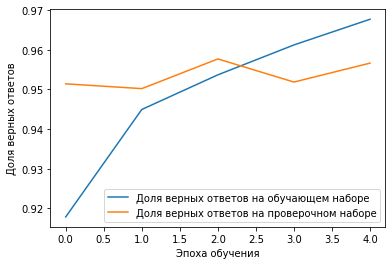

In [28]:
plt.plot(history.history['accuracy'], 
         label='Доля верных ответов на обучающем наборе')
plt.plot(history.history['val_accuracy'], 
         label='Доля верных ответов на проверочном наборе')
plt.xlabel('Эпоха обучения')
plt.ylabel('Доля верных ответов')
plt.legend()
plt.show()

Загружаем модель с лучшей долей правильных ответов на проверочном наборе данных

In [29]:
model.load_weights(model_save_path)

<a id="ai-034-section-06"></a>
## 06 · Оценка выбранных весов

Проверьте порядок load_weights → преобразование test → evaluate.

_Далее — исходные ячейки учебного материала._

## Загружаем набор данных для тестирования

In [30]:
test = pd.read_csv('yelp_review_polarity_csv/test.csv', 
                    header=None, 
                    names=['Class', 'Review'])

In [31]:
test

,Class,Review
0,2,"Contrary to other reviews, I have zero complai..."
1,1,Last summer I had an appointment to get new ti...
2,2,"Friendly staff, same starbucks fair you get an..."
3,1,The food is good. Unfortunately the service is...
4,2,Even when we didn't have a car Filene's Baseme...
...,...,...
37995,1,If I could give 0...I would. Don't do it.
37996,2,Items Selected:\nChocolate Cinnamon Horn\nSmal...
37997,1,Expensive lunch meals. Fried pickles were goo...
37998,1,Highly overpriced and food was cold. Our waitr...


Преобразуем отзывы в числовое представление

Обратите внимание, что нужно использовать токенизатор, обученный на наборе данных train.

In [32]:
test_sequences = tokenizer.texts_to_sequences(test['Review'])

In [33]:
x_test = pad_sequences(test_sequences, maxlen=max_review_len)

In [34]:
x_test[:5]

array([[   9,    1,  546,  148,  274,  165,    2, 1221,    4,   14,  137,
          18,  289,   38, 8346, 2311,  257,  511,   28, 1167,    2,  113,
          60,  568,  520, 1426,   16,   11,   44,   31,   13,    3,   82,
          22,  249,   38,    3,  144,  173,  694, 2235,    7,   40,   72,
           7,   14,   80, 2540, 5951,   23,   69,    9,   21,   14,    7,
        1558,    2,   23, 1696,   14, 1894, 1775,  470,   17,   45,   14,
          52,    2, 1346, 5923,   95,   37,   69,   91, 1024,    2,  311,
          48,    4,   32,    4, 1480, 1037,   19,   40, 4124,    1,  317,
         127,    8,  562,    5,  203,  114,   99,    8,   90,   10, 1168,
         274],
       [   0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,  182, 1243,    3,   24,
          59,  728,    4,   43,  159, 2073,    2,   24,    4,  154,    5,
         315,  190,   4

Правильные ответы

In [35]:
y_test = test['Class'] - 1

In [36]:
y_test

0        1
1        0
2        1
3        0
4        1
        ..
37995    0
37996    1
37997    0
37998    0
37999    0
Name: Class, Length: 38000, dtype: int64

## Оцениваем качество работы сети на тестовом наборе данных

In [37]:
model.evaluate(x_test, y_test, verbose=1)

1188/1188 [==============================] - 11s 10ms/step - loss: 0.1365 - accuracy: 0.9480


[0.136474609375, 0.9480262994766235]

<a id="ai-034-section-07"></a>
## 07 · Разбор своего отзыва

Один текст помогает увидеть ошибки предобработки и порога.

_Далее — исходные ячейки учебного материала._

## Оцениваем тональность на собственном отзыве

In [38]:
text = '''The SmartBurger restaurant is awful. It’s a small shabby place. 
The food is really bad and very expensive.  The host and waiters are rude. 
I will never visit the SmartBurger again!
'''

In [39]:
sequence = tokenizer.texts_to_sequences([text])

In [40]:
sequence

[[1,
  104,
  11,
  692,
  5,
  197,
  5272,
  31,
  1,
  29,
  11,
  61,
  143,
  2,
  42,
  502,
  1,
  1526,
  2,
  1713,
  28,
  401,
  3,
  66,
  88,
  285,
  1,
  108]]

In [41]:
data = pad_sequences(sequence, maxlen=max_review_len)

In [42]:
data

array([[   0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    1,  104,   11,  692,    5,
         197, 5272,   31,    1,   29,   11,   61,  143,    2,   42,  502,
           1, 1526,    2, 1713,   28,  401,    3,   66,   88,  285,    1,
         108]], dtype=int32)

In [43]:
result = model.predict(data)

In [44]:
result

array([[5.6293782e-05]], dtype=float32)

In [45]:
if result[[0]] < 0.5:
    print('Отзыв отрицательный')
else:
    print('Отзыв положительный')


Отзыв отрицательный


<a id="ai-034-practice"></a>
## Проверьте понимание

1. Почему load_weights влияет на смысл итоговой метрики?
2. Можно ли считать тестовым validation_split=0.1?
3. Сохраняется ли токенизатор вместе с файлом весов в исходном коде?

### Один самостоятельный эксперимент

В отдельной копии сравните последнюю и лучшую эпохи на проверочной части, сохранив один финальный тест.

**Критерий успеха:** Для каждой версии указаны номер эпохи и происхождение весов; тест не выбирает победителя.

<a id="ai-034-provenance"></a>
## Источники и ограничения

[Исходный ноутбук и его авторские материалы](https://github.com/safal207/students/blob/d848e04c8f8d6e3e8e42ce15fbd98c00612e0e17/NLP/%D0%9E%D0%BF%D1%80%D0%B5%D0%B4%D0%B5%D0%BB%D0%B5%D0%BD%D0%B8%D0%B5_%D1%82%D0%BE%D0%BD%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D1%81%D1%82%D0%B8_%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2_YELP_%D1%87%D0%B5%D1%80%D0%B5%D0%B7_LSTM_%D1%81%D0%B5%D1%82%D1%8C_%D1%82%D0%BE%D1%87%D0%BD%D0%BE%D1%81%D1%82%D1%8C_95_.ipynb) · репозиторий `safal207/students`.

Исходные подписи, ссылки, авторство, код, изображения и аудио сохранены. Длинные текстовые выводы могут быть сокращены с указанием источника. Архивные результаты не пересчитывались.

### Перед новым запуском

- Основная цепочка близка к notebook 032; это вариант учебного материала, а не независимое подтверждение качества.
- Требуются внешний корпус, совместимая версия Keras и поддержка H5 checkpoint.
- Словарь и настройки preprocessing не экспортируются вместе с весами; одного best_model.h5 недостаточно для полного воспроизведения сервиса.
- Архивное значение в имени файла и результаты прошлых ячеек не перепроверялись.

**Иллюстрации:** обложка направления AI PATH; карта урока подготовлена по содержимому исходных ячеек.